In [ ]:
import pandas as pd

df = pd.read_excel("/Website_Navigation_Traffic_Dataset.xlsx")

df.head()

,Session_ID,Date,Traffic_Source,Device,Landing_Page,Pages_Viewed,Session_Duration_Min,Bounce,Exit_Page,Converted,Navigation_Path
0,S0001,2026-08-01,Organic Search,Desktop,Home,3,1.99,No,Blog,No,Home → Contact → Exit
1,S0002,2026-08-01,Paid Search,Mobile,Products,4,2.83,No,Services,No,Products → Products → Product Details → Exit
2,S0003,2026-08-01,Social,Mobile,Blog,7,3.56,No,Home,Yes,Blog → Products → Product Details → Checkout →...
3,S0004,2026-08-01,Direct,Desktop,Services,2,1.38,No,Products,No,Services → Products → Exit
4,S0005,2026-08-01,Organic Search,Desktop,Blog,5,3.12,No,Services,No,Blog → Products → Product Details → Exit


In [ ]:
df.shape

(500, 11)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Session_ID            500 non-null    object        
 1   Date                  500 non-null    datetime64[ns]
 2   Traffic_Source        500 non-null    object        
 3   Device                500 non-null    object        
 4   Landing_Page          500 non-null    object        
 5   Pages_Viewed          500 non-null    int64         
 6   Session_Duration_Min  500 non-null    float64       
 7   Bounce                500 non-null    object        
 8   Exit_Page             500 non-null    object        
 9   Converted             500 non-null    object        
 10  Navigation_Path       500 non-null    object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(8)
memory usage: 43.1+ KB


In [ ]:
df.describe()

,Date,Pages_Viewed,Session_Duration_Min
count,500,500.000000,500.000000
mean,2026-08-15 00:02:52.800000256,4.020000,3.823980
min,2026-08-01 00:00:00,1.000000,0.200000
25%,2026-08-08 00:00:00,3.000000,1.927500
50%,2026-08-15 00:00:00,4.000000,3.305000
75%,2026-08-22 00:00:00,5.000000,4.982500
max,2026-08-30 00:00:00,10.000000,20.000000
std,NaN,1.697458,2.535284


In [ ]:
traffic_source_counts = df["Traffic_Source"].value_counts()

traffic_source_counts

,count
Traffic_Source,
Organic Search,212
Direct,125
Social,75
Referral,48
Paid Search,40


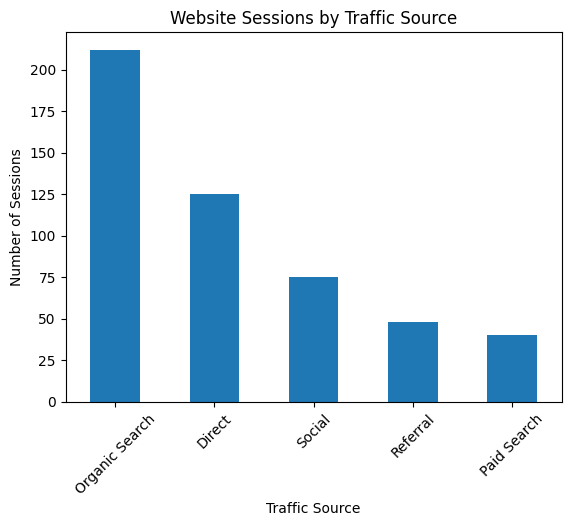

In [ ]:
import matplotlib.pyplot as plt

traffic_source_counts.plot(kind="bar")

plt.title("Website Sessions by Traffic Source")
plt.xlabel("Traffic Source")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=45)
plt.show()

traffic_source_counts

In [ ]:
traffic_percentage = (traffic_source_counts / len(df)) * 100

traffic_percentage.round(2)

,count
Traffic_Source,
Organic Search,42.4
Direct,25.0
Social,15.0
Referral,9.6
Paid Search,8.0


In [ ]:
traffic_analysis = df.groupby("Traffic_Source").agg(
    Sessions=("Session_ID", "count"),
    Average_Pages=("Pages_Viewed", "mean"),
    Average_Duration=("Session_Duration_Min", "mean")
).round(2)

traffic_analysis

,Sessions,Average_Pages,Average_Duration
Traffic_Source,,,
Direct,125,4.01,3.95
Organic Search,212,4.10,3.78
Paid Search,40,4.42,4.08
Referral,48,3.96,4.05
Social,75,3.64,3.47


In [ ]:
bounce_analysis = df.groupby("Traffic_Source").agg(
    Sessions=("Session_ID", "count"),
    Bounced_Sessions=("Bounce", lambda x: (x == "Yes").sum())
)

bounce_analysis["Bounce_Rate"] = (
    bounce_analysis["Bounced_Sessions"] /
    bounce_analysis["Sessions"] * 100
).round(2)

bounce_analysis

,Sessions,Bounced_Sessions,Bounce_Rate
Traffic_Source,,,
Direct,125,20,16.00
Organic Search,212,31,14.62
Paid Search,40,3,7.50
Referral,48,2,4.17
Social,75,11,14.67


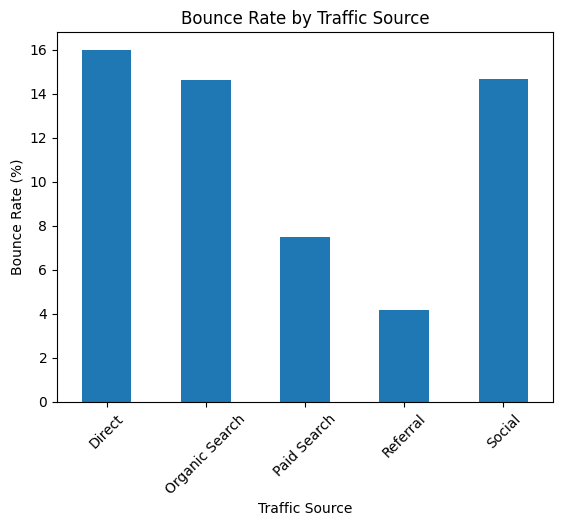

In [ ]:
bounce_analysis["Bounce_Rate"].plot(kind="bar")

plt.title("Bounce Rate by Traffic Source")
plt.xlabel("Traffic Source")
plt.ylabel("Bounce Rate (%)")
plt.xticks(rotation=45)
plt.show()

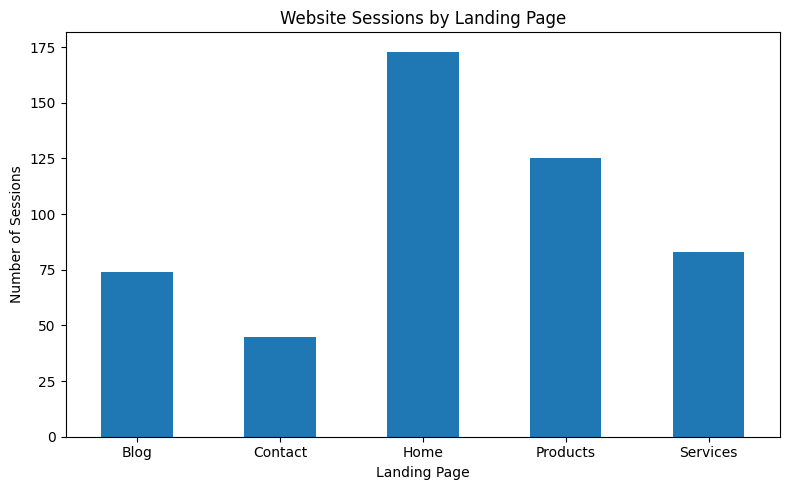

In [ ]:
import matplotlib.pyplot as plt

# Recreate the landing page analysis
landing_page_analysis = df.groupby("Landing_Page").agg(
    Sessions=("Session_ID", "count"),
    Average_Pages=("Pages_Viewed", "mean"),
    Average_Duration=("Session_Duration_Min", "mean")
).round(2)

# Display the graph
plt.figure(figsize=(8, 5))

landing_page_analysis["Sessions"].plot(kind="bar")

plt.title("Website Sessions by Landing Page")
plt.xlabel("Landing Page")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

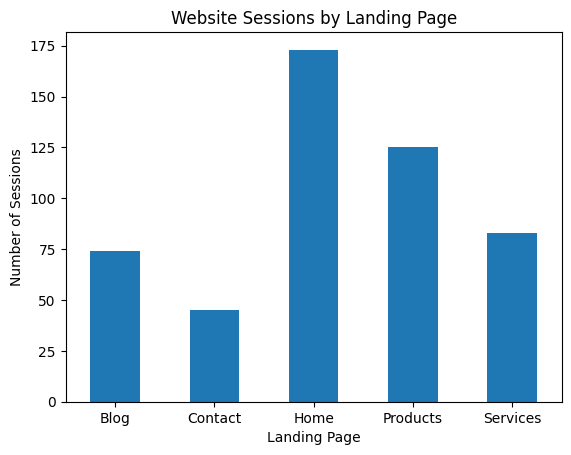

In [ ]:
landing_page_analysis["Sessions"].plot(kind="bar")

plt.title("Website Sessions by Landing Page")
plt.xlabel("Landing Page")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=0)
plt.show()

In [ ]:
device_analysis = df.groupby("Device").agg(
    Sessions=("Session_ID", "count"),
    Average_Pages=("Pages_Viewed", "mean"),
    Average_Duration=("Session_Duration_Min", "mean")
).round(2)

device_analysis

,Sessions,Average_Pages,Average_Duration
Device,,,
Desktop,162,3.81,3.44
Mobile,303,4.14,4.04
Tablet,35,3.91,3.80


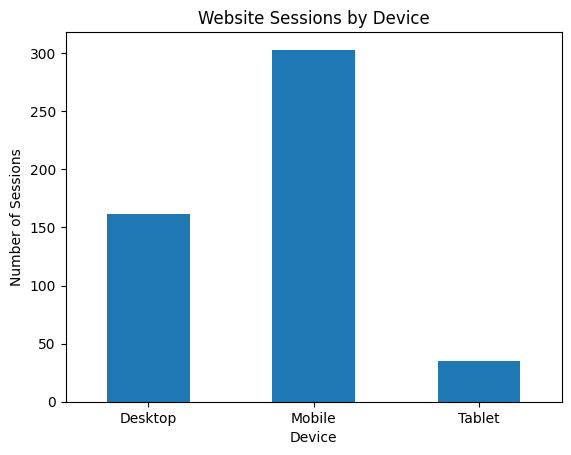

In [ ]:
device_analysis["Sessions"].plot(kind="bar")

plt.title("Website Sessions by Device")
plt.xlabel("Device")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=0)
plt.show()

In [ ]:
daily_sessions = df.groupby("Date")["Session_ID"].count()

daily_sessions

,Session_ID
Date,
2026-08-01,18
2026-08-02,17
2026-08-03,17
2026-08-04,17
2026-08-05,18
2026-08-06,17
2026-08-07,17
2026-08-08,17
2026-08-09,17


In [ ]:
import numpy as np

np.random.seed(10)

df["Date"] = np.random.choice(
    pd.date_range("2026-08-01", "2026-08-30"),
    size=len(df)
)

df["Date"] = pd.to_datetime(df["Date"])

daily_sessions = df.groupby("Date")["Session_ID"].count().sort_index()

daily_sessions

,Session_ID
Date,
2026-08-01,23
2026-08-02,15
2026-08-03,11
2026-08-04,10
2026-08-05,13
2026-08-06,19
2026-08-07,14
2026-08-08,15
2026-08-09,16


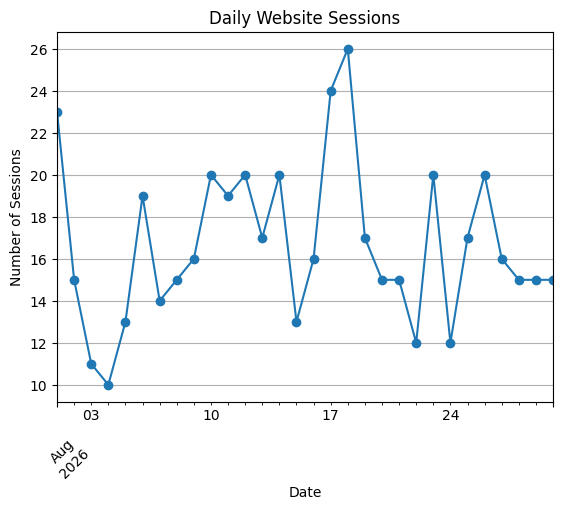

In [ ]:
daily_sessions.plot(kind="line", marker="o")

plt.title("Daily Website Sessions")
plt.xlabel("Date")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [ ]:
exit_page_counts = df["Exit_Page"].value_counts()

exit_page_counts

,count
Exit_Page,
Services,117
Products,107
Home,99
Contact,91
Blog,86


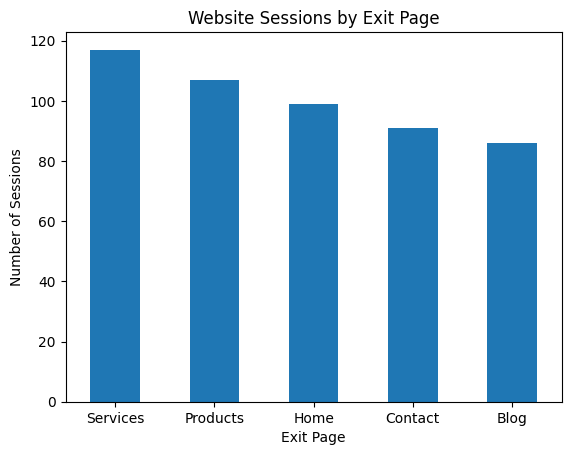

In [ ]:
exit_page_counts.plot(kind="bar")

plt.title("Website Sessions by Exit Page")
plt.xlabel("Exit Page")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=0)
plt.show()

In [ ]:
navigation_paths = df["Navigation_Path"].value_counts()

navigation_paths.head(10)

,count
Navigation_Path,
Home → Products → Product Details → Exit,89
Products → Products → Product Details → Exit,59
Services → Products → Product Details → Exit,47
Blog → Products → Product Details → Exit,46
Products → Services → Exit,21
Contact → Products → Product Details → Exit,20
Home → Services → Exit,20
Home → Blog → Exit,19
Home → Products → Exit,17


In [ ]:
total_sessions = len(df)
total_page_views = df["Pages_Viewed"].sum()
average_pages = df["Pages_Viewed"].mean()
average_duration = df["Session_Duration_Min"].mean()
bounce_rate = (df["Bounce"] == "Yes").mean() * 100
total_conversions = (df["Converted"] == "Yes").sum()
conversion_rate = (df["Converted"] == "Yes").mean() * 100

print("Total Sessions:", total_sessions)
print("Total Page Views:", total_page_views)
print("Average Pages per Session:", round(average_pages, 2))
print("Average Session Duration:", round(average_duration, 2), "minutes")
print("Bounce Rate:", round(bounce_rate, 2), "%")
print("Total Conversions:", total_conversions)
print("Conversion Rate:", round(conversion_rate, 2), "%")

Total Sessions: 500
Total Page Views: 2010
Average Pages per Session: 4.02
Average Session Duration: 3.82 minutes
Bounce Rate: 13.4 %
Total Conversions: 43
Conversion Rate: 8.6 %


In [ ]:
conversion_analysis = df.groupby("Traffic_Source").agg(
    Sessions=("Session_ID", "count"),
    Conversions=("Converted", lambda x: (x == "Yes").sum())
)

conversion_analysis["Conversion_Rate"] = (
    conversion_analysis["Conversions"] /
    conversion_analysis["Sessions"] * 100
).round(2)

conversion_analysis

,Sessions,Conversions,Conversion_Rate
Traffic_Source,,,
Direct,125,9,7.20
Organic Search,212,19,8.96
Paid Search,40,3,7.50
Referral,48,5,10.42
Social,75,7,9.33


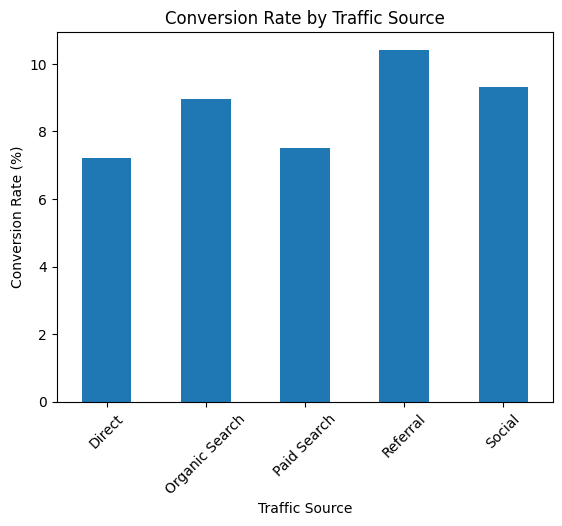

In [ ]:
conversion_analysis["Conversion_Rate"].plot(kind="bar")

plt.title("Conversion Rate by Traffic Source")
plt.xlabel("Traffic Source")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=45)
plt.show()

In [ ]:
device_conversion = df.groupby("Device").agg(
    Sessions=("Session_ID", "count"),
    Conversions=("Converted", lambda x: (x == "Yes").sum())
)

device_conversion["Conversion_Rate"] = (
    device_conversion["Conversions"] /
    device_conversion["Sessions"] * 100
).round(2)

device_conversion

,Sessions,Conversions,Conversion_Rate
Device,,,
Desktop,162,14,8.64
Mobile,303,25,8.25
Tablet,35,4,11.43


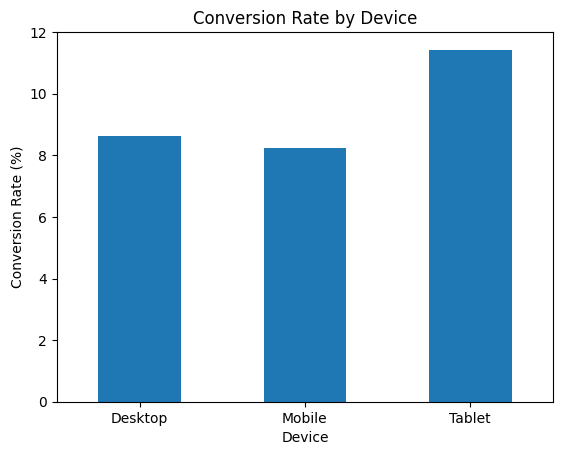

In [ ]:
device_conversion["Conversion_Rate"].plot(kind="bar")

plt.title("Conversion Rate by Device")
plt.xlabel("Device")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=0)
plt.show()

In [ ]:
summary = pd.DataFrame({
    "Metric": [
        "Total Sessions",
        "Total Page Views",
        "Average Pages per Session",
        "Average Session Duration (minutes)",
        "Bounce Rate (%)",
        "Total Conversions",
        "Conversion Rate (%)"
    ],
    "Value": [
        total_sessions,
        total_page_views,
        round(average_pages, 2),
        round(average_duration, 2),
        round(bounce_rate, 2),
        total_conversions,
        round(conversion_rate, 2)
    ]
})

summary

,Metric,Value
0,Total Sessions,500.00
1,Total Page Views,2010.00
2,Average Pages per Session,4.02
3,Average Session Duration (minutes),3.82
4,Bounce Rate (%),13.40
5,Total Conversions,43.00
6,Conversion Rate (%),8.60


In [ ]:
summary.to_csv("project_summary.csv", index=False)

traffic_analysis.to_csv("traffic_source_analysis.csv")
bounce_analysis.to_csv("bounce_rate_analysis.csv")
landing_page_analysis.to_csv("landing_page_analysis.csv")
device_analysis.to_csv("device_analysis.csv")
conversion_analysis.to_csv("conversion_analysis.csv")
device_conversion.to_csv("device_conversion_analysis.csv")

print("Analysis results saved successfully.")

Analysis results saved successfully.


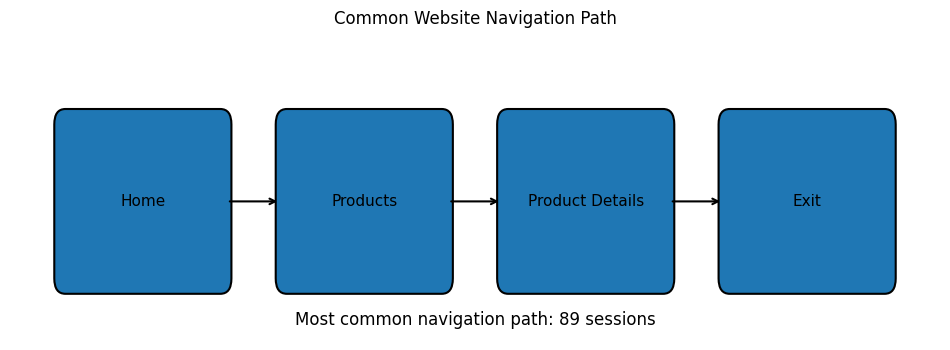

In [ ]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(12, 4))

steps = ["Home", "Products", "Product Details", "Exit"]
x_positions = [0, 1, 2, 3]

for i, (step, x) in enumerate(zip(steps, x_positions)):
    box = FancyBboxPatch(
        (x - 0.35, 0.2),
        0.7,
        0.5,
        boxstyle="round,pad=0.05",
        linewidth=1.5
    )
    ax.add_patch(box)
    ax.text(x, 0.45, step, ha="center", va="center", fontsize=11)

    if i < len(steps) - 1:
        ax.annotate(
            "",
            xy=(x + 0.62, 0.45),
            xytext=(x + 0.38, 0.45),
            arrowprops=dict(arrowstyle="->", linewidth=1.5)
        )

ax.text(
    1.5, 0.05,
    "Most common navigation path: 89 sessions",
    ha="center",
    fontsize=12
)

ax.set_xlim(-0.6, 3.6)
ax.set_ylim(0, 1)
ax.axis("off")

plt.title("Common Website Navigation Path")
plt.show()

In [ ]:
import os

os.makedirs("project_graphs", exist_ok=True)

print("Project graphs folder created successfully.")

Project graphs folder created successfully.


In [ ]:
# Save all project graphs

# 1. Traffic Source
plt.figure(figsize=(8, 5))
traffic_source_counts.plot(kind="bar")
plt.title("Website Sessions by Traffic Source")
plt.xlabel("Traffic Source")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("project_graphs/01_traffic_source.png", dpi=300)
plt.close()

# 2. Bounce Rate
plt.figure(figsize=(8, 5))
bounce_analysis["Bounce_Rate"].plot(kind="bar")
plt.title("Bounce Rate by Traffic Source")
plt.xlabel("Traffic Source")
plt.ylabel("Bounce Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("project_graphs/02_bounce_rate.png", dpi=300)
plt.close()

# 3. Landing Page
plt.figure(figsize=(8, 5))
landing_page_analysis["Sessions"].plot(kind="bar")
plt.title("Website Sessions by Landing Page")
plt.xlabel("Landing Page")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("project_graphs/03_landing_page.png", dpi=300)
plt.close()

# 4. Device
plt.figure(figsize=(8, 5))
device_analysis["Sessions"].plot(kind="bar")
plt.title("Website Sessions by Device")
plt.xlabel("Device")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("project_graphs/04_device.png", dpi=300)
plt.close()

# 5. Daily Traffic
plt.figure(figsize=(10, 5))
daily_sessions.plot(kind="line", marker="o")
plt.title("Daily Website Sessions")
plt.xlabel("Date")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.savefig("project_graphs/05_daily_traffic.png", dpi=300)
plt.close()

# 6. Exit Page
plt.figure(figsize=(8, 5))
exit_page_counts.plot(kind="bar")
plt.title("Website Sessions by Exit Page")
plt.xlabel("Exit Page")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("project_graphs/06_exit_page.png", dpi=300)
plt.close()

# 7. Conversion Rate by Traffic Source
plt.figure(figsize=(8, 5))
conversion_analysis["Conversion_Rate"].plot(kind="bar")
plt.title("Conversion Rate by Traffic Source")
plt.xlabel("Traffic Source")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("project_graphs/07_conversion_rate.png", dpi=300)
plt.close()

# 8. Conversion Rate by Device
plt.figure(figsize=(8, 5))
device_conversion["Conversion_Rate"].plot(kind="bar")
plt.title("Conversion Rate by Device")
plt.xlabel("Device")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("project_graphs/08_device_conversion.png", dpi=300)
plt.close()

print("All 8 project graphs have been saved successfully.")

All 8 project graphs have been saved successfully.


In [ ]:
# Check for missing values

missing_values = df.isnull().sum()

missing_values

,0
Session_ID,0
Date,0
Traffic_Source,0
Device,0
Landing_Page,0
Pages_Viewed,0
Session_Duration_Min,0
Bounce,0
Exit_Page,0
Converted,0


In [ ]:
# Check for duplicate records

duplicate_count = df.duplicated().sum()

duplicate_count

np.int64(0)

In [ ]:
# Check unique values in important categorical columns

for col in ["Traffic_Source", "Device", "Landing_Page", "Bounce", "Converted"]:
    print(f"\n{col}:")
    print(df[col].unique())


Traffic_Source:
['Organic Search' 'Paid Search' 'Social' 'Direct' 'Referral']

Device:
['Desktop' 'Mobile' 'Tablet']

Landing_Page:
['Home' 'Products' 'Blog' 'Services' 'Contact']

Bounce:
['No' 'Yes']

Converted:
['No' 'Yes']


In [ ]:
# Save the processed dataset

df.to_csv("website_analytics_processed.csv", index=False)

print("Processed dataset saved successfully.")

Processed dataset saved successfully.


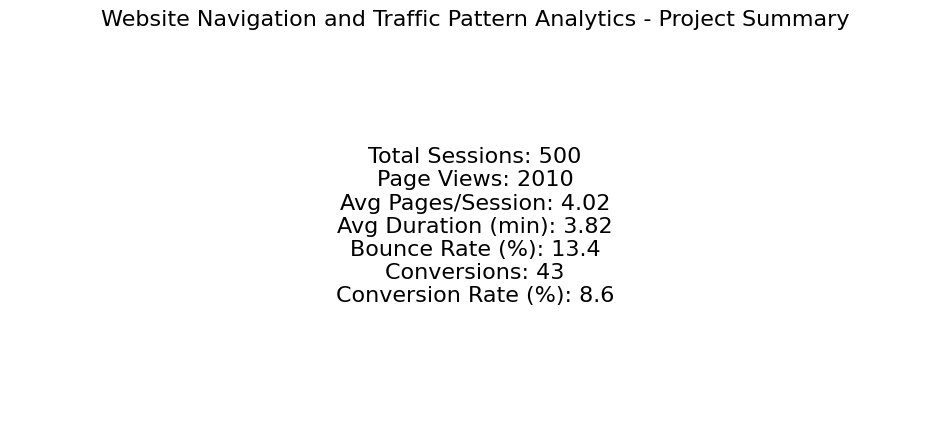

In [ ]:
import matplotlib.pyplot as plt

# Main project metrics
metrics = {
    "Total Sessions": total_sessions,
    "Page Views": total_page_views,
    "Avg Pages/Session": round(average_pages, 2),
    "Avg Duration (min)": round(average_duration, 2),
    "Bounce Rate (%)": round(bounce_rate, 2),
    "Conversions": total_conversions,
    "Conversion Rate (%)": round(conversion_rate, 2)
}

fig, ax = plt.subplots(figsize=(12, 5))

ax.axis("off")

text = "\n".join(
    [f"{key}: {value}" for key, value in metrics.items()]
)

ax.text(
    0.5, 0.5,
    text,
    ha="center",
    va="center",
    fontsize=16
)

plt.title("Website Navigation and Traffic Pattern Analytics - Project Summary",
          fontsize=16)

plt.show()

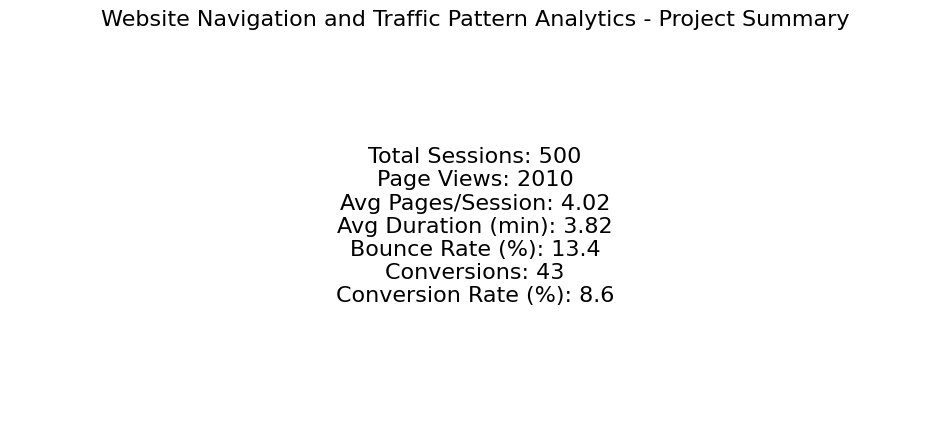

Project summary image saved successfully.


In [ ]:
# Save the project summary dashboard

plt.figure(figsize=(12, 5))

plt.axis("off")

text = "\n".join(
    [f"{key}: {value}" for key, value in metrics.items()]
)

plt.text(
    0.5, 0.5,
    text,
    ha="center",
    va="center",
    fontsize=16
)

plt.title(
    "Website Navigation and Traffic Pattern Analytics - Project Summary",
    fontsize=16
)

plt.savefig(
    "project_graphs/09_project_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Project summary image saved successfully.")

In [ ]:
import os

print("Project graph files:")
print(os.listdir("project_graphs"))

print("\nAnalysis files:")
for file in [
    "project_summary.csv",
    "traffic_source_analysis.csv",
    "bounce_rate_analysis.csv",
    "landing_page_analysis.csv",
    "device_analysis.csv",
    "conversion_analysis.csv",
    "device_conversion_analysis.csv",
    "website_analytics_processed.csv"
]:
    print(file, "✓" if os.path.exists(file) else "✗")

Project graph files:
['02_bounce_rate.png', '05_daily_traffic.png', '03_landing_page.png', '01_traffic_source.png', '07_conversion_rate.png', '08_device_conversion.png', '06_exit_page.png', '09_project_summary.png', '04_device.png']

Analysis files:
project_summary.csv ✓
traffic_source_analysis.csv ✓
bounce_rate_analysis.csv ✓
landing_page_analysis.csv ✓
device_analysis.csv ✓
conversion_analysis.csv ✓
device_conversion_analysis.csv ✓
website_analytics_processed.csv ✓


In [ ]:
# Validate numerical values

print("Pages Viewed - Min:", df["Pages_Viewed"].min())
print("Pages Viewed - Max:", df["Pages_Viewed"].max())

print("Session Duration - Min:", df["Session_Duration_Min"].min())
print("Session Duration - Max:", df["Session_Duration_Min"].max())

print("Total rows:", len(df))


Pages Viewed - Min: 1
Pages Viewed - Max: 10
Session Duration - Min: 0.2
Session Duration - Max: 20.0
Total rows: 500
